In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelBinarizer
from scipy.stats import kurtosis, skew

%matplotlib inline

# Load Dataset

In [2]:
df = pd.read_csv(r"C:\Users\pradn\Downloads\Mall_Customers.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [4]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [5]:
df.drop("CustomerID", axis=1, inplace=True)
df.head()

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


In [6]:
df.columns = [
    "Gender",
    "Age",
    "Annual_Income",
    "Spending_Score(1-100)"
]

df.head()

,Gender,Age,Annual_Income,Spending_Score(1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40


# Statistical summary

In [7]:
df.describe()

,Age,Annual_Income,Spending_Score(1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


In [8]:
df.select_dtypes(include="number").corr()

,Age,Annual_Income,Spending_Score(1-100)
Age,1.000000,-0.012398,-0.327227
Annual_Income,-0.012398,1.000000,0.009903
Spending_Score(1-100),-0.327227,0.009903,1.000000


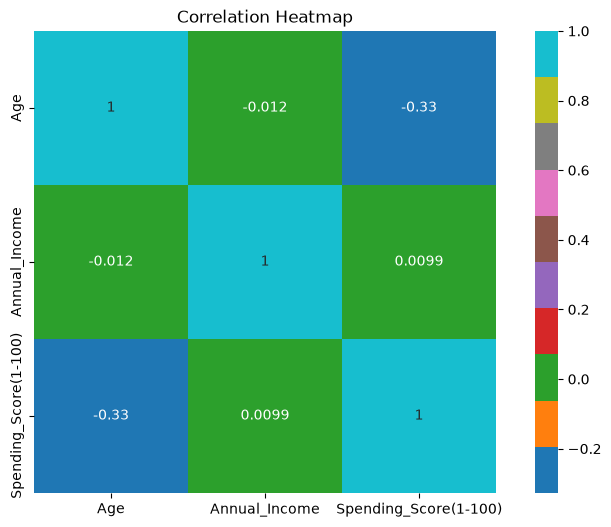

In [9]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    square=True,
    cmap="tab10"
)

plt.title("Correlation Heatmap")
plt.show()

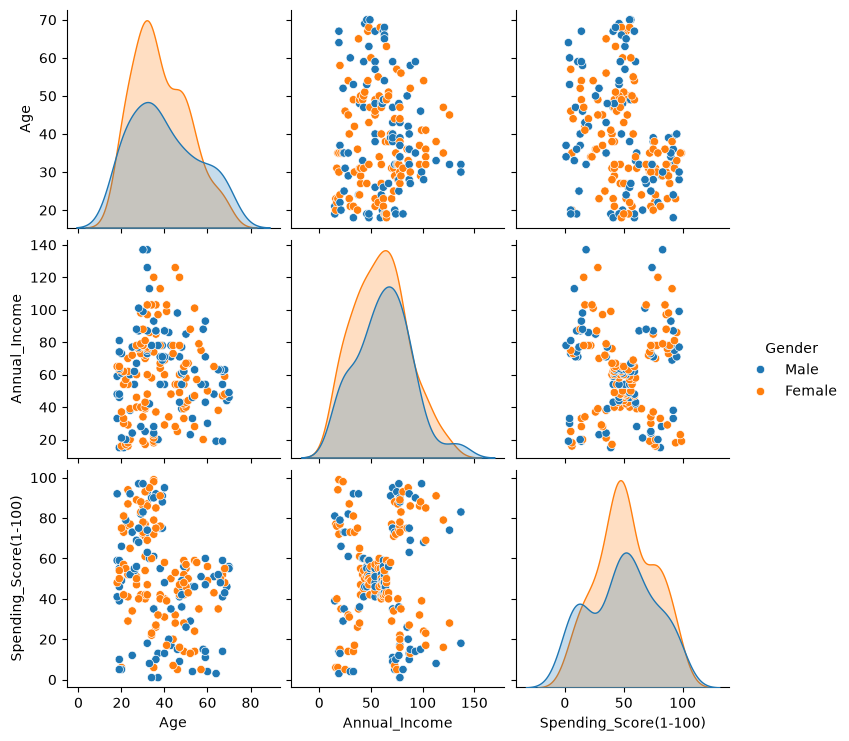

In [10]:
sns.pairplot(df, hue="Gender")
plt.show()

Boxplot

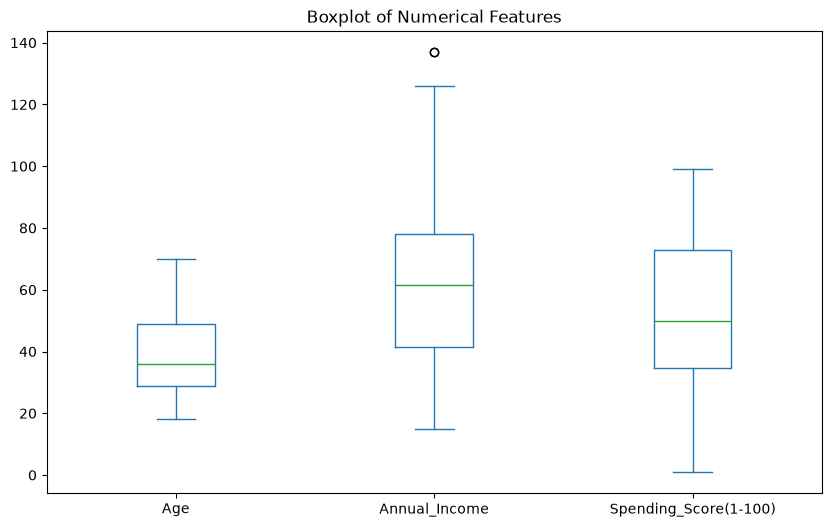

In [11]:
df.select_dtypes(include="number").plot(
    kind="box",
    figsize=(10, 6)
)

plt.title("Boxplot of Numerical Features")
plt.show()

Age Distribution

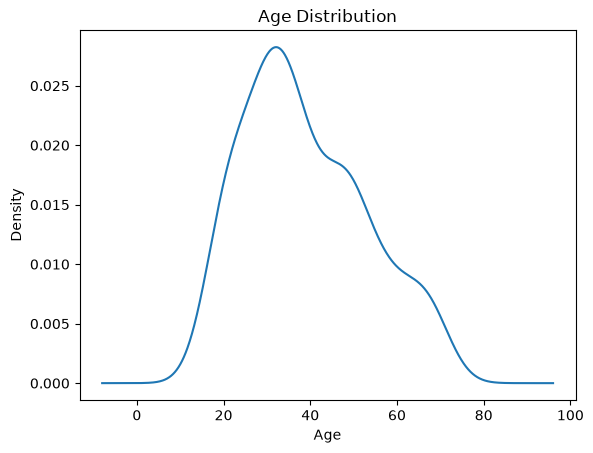

In [12]:
df["Age"].plot.kde()

plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

Annual income distribution

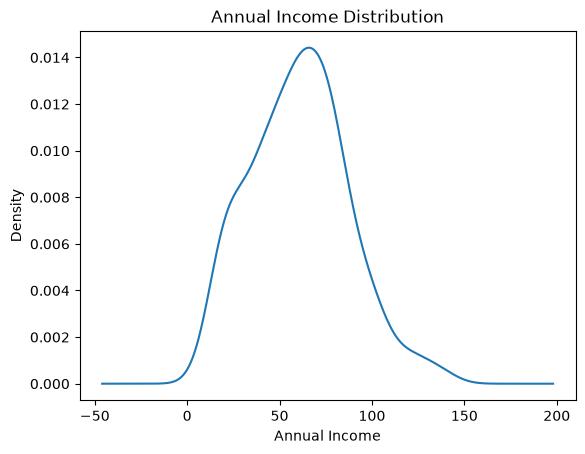

In [13]:
df["Annual_Income"].plot.kde()

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")
plt.show()

Spending score distribution

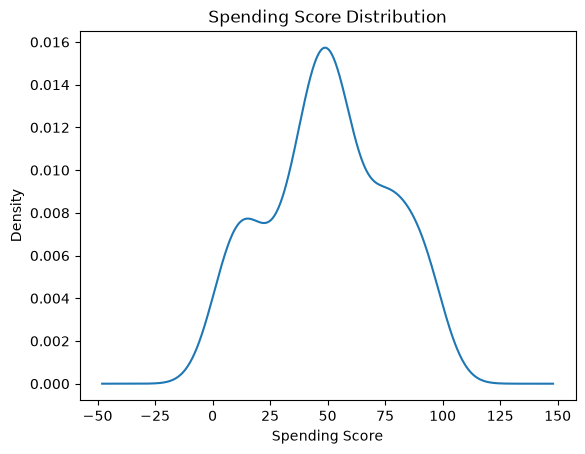

In [15]:
df["Spending_Score(1-100)"].plot.kde()

plt.title("Spending Score Distribution")
plt.xlabel("Spending Score")
plt.show()

Gender vs annual income

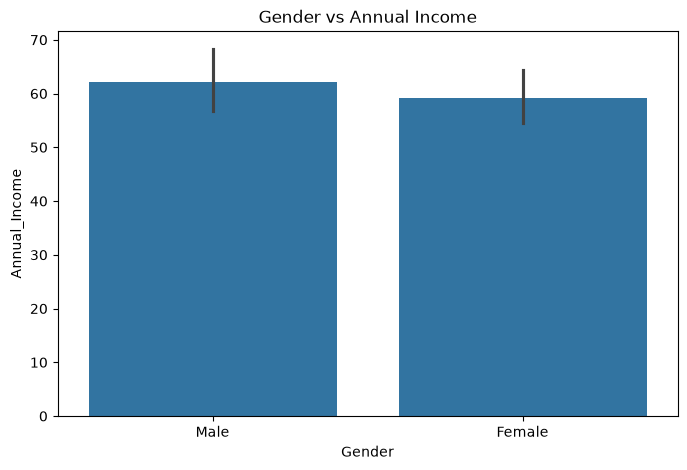

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Gender",
    y="Annual_Income"
)

plt.title("Gender vs Annual Income")
plt.show()

Age vs annual income

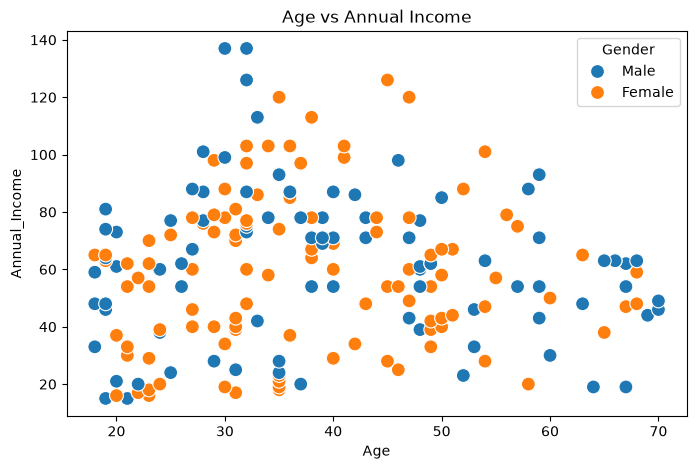

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Annual_Income",
    hue="Gender",
    s=100
)

plt.title("Age vs Annual Income")
plt.show()

Spending score vs annual income

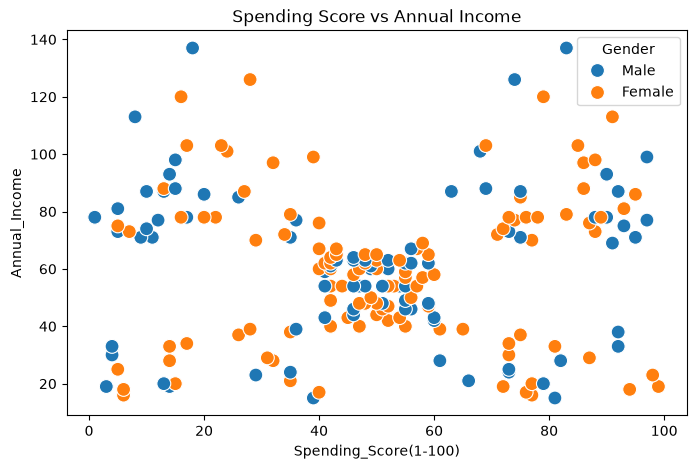

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Spending_Score(1-100)",
    y="Annual_Income",
    hue="Gender",
    s=100
)

plt.title("Spending Score vs Annual Income")
plt.show()

Generate profiling report

In [20]:
df.describe(include="all").to_csv(
    "Mall_Customers_Report.csv"
)

html_report = df.describe(include="all").to_html()

with open(
    "Mall_Customers_Report.html",
    "w",
    encoding="utf-8"
) as file:
    file.write(
        "<html><head><title>Mall Customers Report</title></head>"
        "<body><h1>Mall Customers Report</h1>"
        + html_report +
        "</body></html>"
    )

print("Report generated successfully.")

Report generated successfully.


In [40]:
from IPython.display import IFrame, display

display(IFrame("Mall_Customers_Report.html", width="100%", height=600))

Encode Gender

In [21]:
encoder = LabelBinarizer()
df["Gender"] = encoder.fit_transform(df["Gender"])
df.head()

,Gender,Age,Annual_Income,Spending_Score(1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40


Calculate skewness

In [22]:
skew(df.select_dtypes(include="number"), axis=0)

array([ 0.24174689,  0.48191947,  0.31942368, -0.04686531])

Calculate kurtosis

In [23]:
kurtosis(
    df.select_dtypes(include="number"),
    axis=0
)

array([-1.94155844, -0.68475139, -0.12589283, -0.83595827])

Calculate WCSS

In [24]:
cluster_no = list(range(1, 12))
WCSS = []

for i in cluster_no:
    model = KMeans(
        n_clusters=i,
        init="k-means++",
        random_state=42,
        n_init=10
    )

    model.fit(df)
    WCSS.append(model.inertia_)

print(WCSS)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window

[308862.06000000006, 212889.44245524303, 143391.59236035676, 104414.67534220168, 75399.61541401484, 58348.641363315044, 51130.69008126377, 44687.235534005464, 40857.18667502089, 37175.97669994118, 34615.45297332297]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Plot Elbow graph

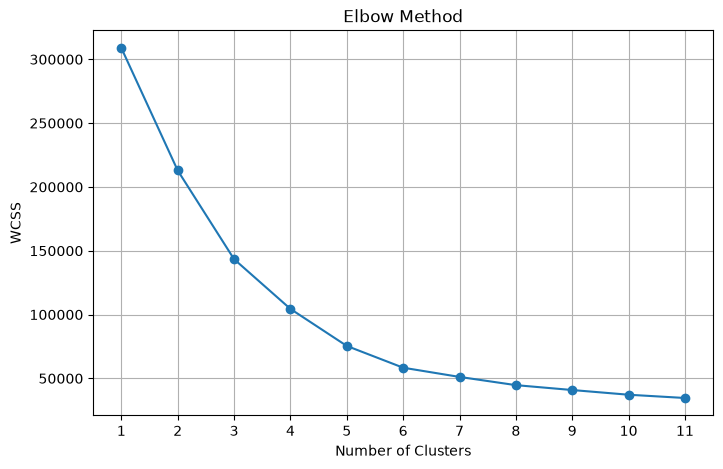

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(cluster_no, WCSS, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(cluster_no)
plt.grid(True)

plt.show()

Train the model

In [26]:
cluster = KMeans(
    n_clusters=4,
    init="k-means++",
    random_state=42,
    n_init=10
)
df["Cluster_No"] = cluster.fit_predict(
    df[[
        "Gender",
        "Age",
        "Annual_Income",
        "Spending_Score(1-100)"
    ]]
)
df.head()

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Gender,Age,Annual_Income,Spending_Score(1-100),Cluster_No
0,1,19,15,39,2
1,1,21,15,81,2
2,0,20,16,6,0
3,0,23,16,77,2
4,0,31,17,40,0


Display cluster centers

In [28]:
cluster.cluster_centers_

array([[ 0.37894737, 44.89473684, 48.70526316, 42.63157895],
       [ 0.46153846, 32.69230769, 86.53846154, 82.12820513],
       [ 0.5       , 24.82142857, 28.71428571, 74.25      ],
       [ 0.52631579, 40.39473684, 87.        , 18.63157895]])

Display dataset with cluster labels

In [29]:
df

,Gender,Age,Annual_Income,Spending_Score(1-100),Cluster_No
0,1,19,15,39,2
1,1,21,15,81,2
2,0,20,16,6,0
3,0,23,16,77,2
4,0,31,17,40,0
...,...,...,...,...,...
195,0,35,120,79,1
196,0,45,126,28,3
197,1,32,126,74,1
198,1,32,137,18,3


Visualize the clusters in 3D

3D scatter plot

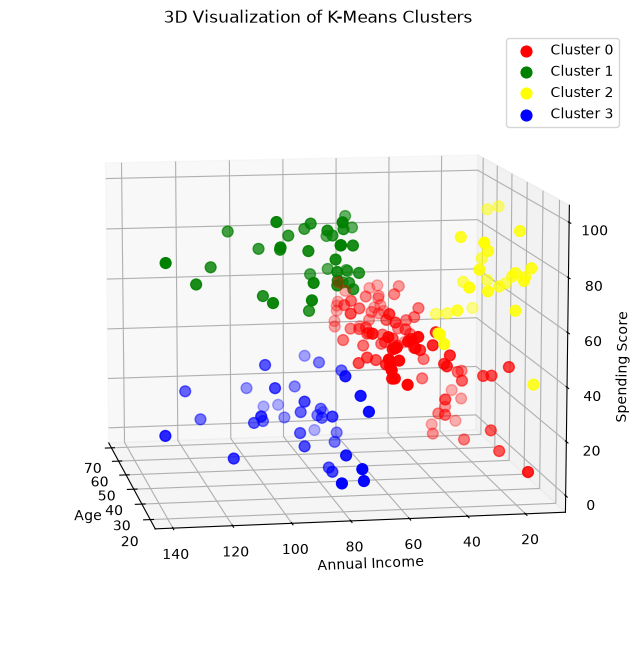

In [30]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection="3d")

colors = ["red", "green", "yellow", "blue"]
for i in range(4):
    cluster_data = df[df["Cluster_No"] == i]

    ax.scatter(
        cluster_data["Age"],
        cluster_data["Annual_Income"],
        cluster_data["Spending_Score(1-100)"],
        color=colors[i],
        label=f"Cluster {i}",
        s=60
    )
ax.set_xlabel("Age")
ax.set_ylabel("Annual Income")
ax.set_zlabel("Spending Score")

ax.set_title("3D Visualization of K-Means Clusters")
ax.view_init(elev=10, azim=170)
ax.legend()
plt.show()

Mean of each cluster

In [31]:
df.groupby("Cluster_No")[
    ["Age", "Annual_Income", "Spending_Score(1-100)"]
].mean()

,Age,Annual_Income,Spending_Score(1-100)
Cluster_No,,,
0,44.894737,48.705263,42.631579
1,32.692308,86.538462,82.128205
2,24.821429,28.714286,74.250000
3,40.394737,87.000000,18.631579


Minimum values

In [32]:
df.groupby("Cluster_No")[
    ["Age", "Annual_Income", "Spending_Score(1-100)"]
].min()

,Age,Annual_Income,Spending_Score(1-100)
Cluster_No,,,
0,18,16,3
1,27,69,63
2,18,15,39
3,19,70,1


Maximum values

In [34]:
df.groupby("Cluster_No")[
    ["Age", "Annual_Income", "Spending_Score(1-100)"]
].max()

,Age,Annual_Income,Spending_Score(1-100)
Cluster_No,,,
0,70,69,60
1,40,137,97
2,35,48,99
3,59,137,40


Standard deviation

In [35]:
df.groupby("Cluster_No")[
    ["Age", "Annual_Income", "Spending_Score(1-100)"]
].std()

,Age,Annual_Income,Spending_Score(1-100)
Cluster_No,,,
0,15.341831,14.522817,14.713616
1,3.728650,16.312485,9.364489
2,5.571446,10.384665,14.075524
3,11.376931,16.271348,10.915947


Number of customers in each cluster

In [36]:
df["Cluster_No"].value_counts().sort_index()

Cluster_No
0    95
1    39
2    28
3    38
Name: count, dtype: int64

Save final clustered dataset

In [37]:
df.to_csv("Mall_Customers_Clustered.csv", index=False)

print("K-Means clustering completed successfully!")
print("Clustered dataset saved successfully.")

K-Means clustering completed successfully!
Clustered dataset saved successfully.


In [39]:
%pip install ydata-profiling

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,